<a href="https://colab.research.google.com/github/SobiaNoorAI/cxr-foundation-model-shift-robustness/blob/main/notebooks/05_hospital_shortcut_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup

In [1]:
# Runtime T4 GPU
from google.colab import drive
drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/phd_projects/cxr_shift"
SEED = 42
!unzip -q -n {BASE}/data_512.zip -d /content

df = pd.read_csv(f"{BASE}/metadata.csv")
paths = df.path512.tolist()
assert all(os.path.exists(p) for p in paths)
ENC = ["resnet50_imagenet", "dinov2_base", "rad_dino"]
CLEAN = {k: np.load(f"{BASE}/features/{k}.npy") for k in ENC}
y, hosp = df.label.values, df.hospital.values
yh = (hosp == "montgomery").astype(int)       # target for the "which hospital?" test
os.makedirs(f"{BASE}/results", exist_ok=True)

Mounted at /content/drive


## helpers

In [2]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def make_model():
    return make_pipeline(StandardScaler(),
        LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], cv=5,
                             scoring="roc_auc", max_iter=5000, random_state=SEED))

def boot_auc(y_true, scores, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    a = [roc_auc_score(y_true[i], scores[i]) for i in
         (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n))]
    lo, hi = np.percentile(a, [2.5, 97.5])
    return roc_auc_score(y_true, scores), lo, hi

def hospital_auc(X, mask):
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    s = cross_val_predict(make_model(), X[mask], yh[mask], cv=skf, method="predict_proba")[:, 1]
    return boot_auc(yh[mask], s, n=500)

## Part A, can a classifier tell the hospital?

In [3]:
from PIL import Image
# Tiny 32x32 grayscale pixel vectors as a "no deep model" baseline
PIX = np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR),
                           dtype=np.float32).ravel() / 255 for p in paths])
FEATS = {**CLEAN, "raw_pixels_32x32": PIX}

rows = []
for name, X in FEATS.items():
    for subset, m in [("all images", np.ones(len(y), bool)),
                      ("normal only", y == 0), ("TB only", y == 1)]:
        auc, lo, hi = hospital_auc(X, m)
        rows.append(dict(features=name, subset=subset, hospital_AUROC=auc, CI_low=lo, CI_high=hi))
partA = pd.DataFrame(rows)
partA.round(4).to_csv(f"{BASE}/results/05_hospital_predictability.csv", index=False)
partA.round(3)

,features,subset,hospital_AUROC,CI_low,CI_high
0,resnet50_imagenet,all images,1.0,1.0,1.0
1,resnet50_imagenet,normal only,1.0,1.0,1.0
2,resnet50_imagenet,TB only,1.0,1.0,1.0
3,dinov2_base,all images,1.0,1.0,1.0
4,dinov2_base,normal only,1.0,1.0,1.0
5,dinov2_base,TB only,1.0,1.0,1.0
6,rad_dino,all images,1.0,1.0,1.0
7,rad_dino,normal only,1.0,1.0,1.0
8,rad_dino,TB only,1.0,1.0,1.0
9,raw_pixels_32x32,all images,1.0,1.0,1.0


## Part B, crop away the edges and re-extract features

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

100%|██████████| 50/50 [00:55<00:00,  1.10s/it]


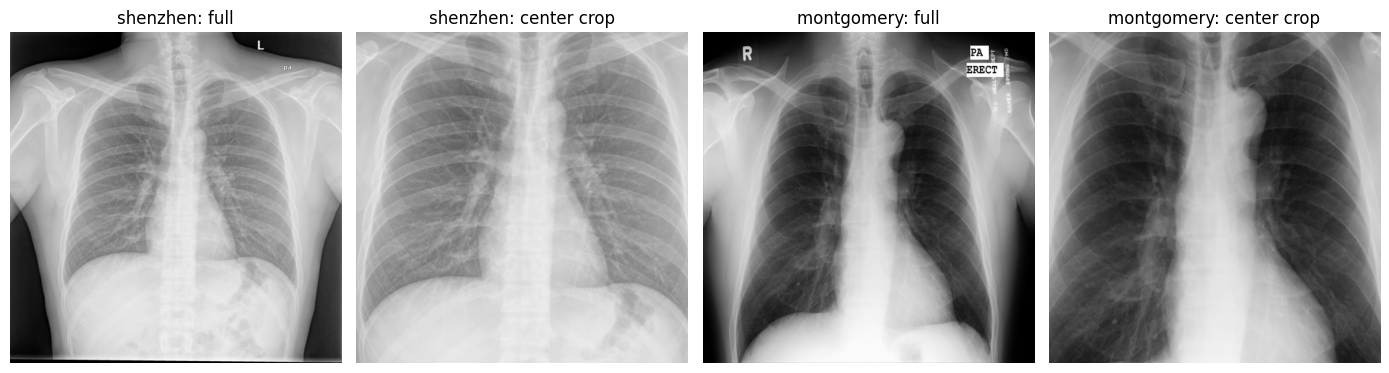

In [4]:
import torch, timm
from tqdm import tqdm
from transformers import AutoImageProcessor, AutoModel
device = "cuda"

class Enc:
    def __init__(self, name):
        self.name = name
        if name == "resnet50_imagenet":
            self.model = timm.create_model("resnet50", pretrained=True, num_classes=0).to(device).eval()
            self.tf = timm.data.create_transform(**timm.data.resolve_data_config({}, model=self.model))
        else:
            hf = {"dinov2_base": "facebook/dinov2-base", "rad_dino": "microsoft/rad-dino"}[name]
            self.proc = AutoImageProcessor.from_pretrained(hf)
            self.model = AutoModel.from_pretrained(hf).to(device).eval().half()
    @torch.no_grad()
    def __call__(self, imgs):
        if self.name == "resnet50_imagenet":
            return self.model(torch.stack([self.tf(i) for i in imgs]).to(device)).cpu().numpy()
        x = self.proc(images=imgs, return_tensors="pt")["pixel_values"].to(device).half()
        return self.model(pixel_values=x).pooler_output.float().cpu().numpy()

CROP = 0.15    # remove 15% from every side
def center_crop(img):
    w, h = img.size
    return img.crop((int(w * CROP), int(h * CROP), int(w * (1 - CROP)), int(h * (1 - CROP))))

out = f"{BASE}/features_corrupt/center_crop.npz"
if not os.path.exists(out):
    encs = {k: Enc(k) for k in ENC}
    feats = {k: [] for k in ENC}
    for i in tqdm(range(0, len(paths), 16)):
        imgs = [center_crop(Image.open(p).convert("RGB")) for p in paths[i:i + 16]]
        for k in ENC:
            feats[k].append(encs[k](imgs))
    np.savez(out, **{k: np.concatenate(v) for k, v in feats.items()})
CROPF = np.load(out)

# Show one crop from each hospital so you can see what was removed
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for j, h in enumerate(["shenzhen", "montgomery"]):
    p = df[df.hospital == h].path512.iloc[0]
    im = Image.open(p).convert("RGB")
    ax[2 * j].imshow(im); ax[2 * j].set_title(f"{h}: full")
    ax[2 * j + 1].imshow(center_crop(im)); ax[2 * j + 1].set_title(f"{h}: center crop")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{BASE}/results/05_crop_examples.png", dpi=150); plt.show()

## cross-hospital TB results, full image vs cropped

In [5]:
rows = []
for enc in ENC:
    for tr, te in [("shenzhen", "montgomery"), ("montgomery", "shenzhen")]:
        for version, F in [("full image", CLEAN), ("center crop", CROPF)]:
            X = F[enc]
            mdl = make_model().fit(X[hosp == tr], y[hosp == tr])
            s = mdl.predict_proba(X[hosp == te])[:, 1]
            auc, lo, hi = boot_auc(y[hosp == te], s)
            rows.append(dict(encoder=enc, direction=f"{tr} → {te}", version=version,
                             AUROC=auc, CI_low=lo, CI_high=hi))
partB = pd.DataFrame(rows)
partB.round(4).to_csv(f"{BASE}/results/05_crop_ablation.csv", index=False)
partB.round(3)

,encoder,direction,version,AUROC,CI_low,CI_high
0,resnet50_imagenet,shenzhen → montgomery,full image,0.557,0.453,0.650
1,resnet50_imagenet,shenzhen → montgomery,center crop,0.738,0.648,0.821
2,resnet50_imagenet,montgomery → shenzhen,full image,0.675,0.637,0.717
3,resnet50_imagenet,montgomery → shenzhen,center crop,0.736,0.696,0.775
4,dinov2_base,shenzhen → montgomery,full image,0.836,0.762,0.900
5,dinov2_base,shenzhen → montgomery,center crop,0.827,0.749,0.891
6,dinov2_base,montgomery → shenzhen,full image,0.746,0.708,0.781
7,dinov2_base,montgomery → shenzhen,center crop,0.745,0.708,0.784
8,rad_dino,shenzhen → montgomery,full image,0.970,0.944,0.989
9,rad_dino,shenzhen → montgomery,center crop,0.967,0.938,0.988


## Part B’s hospital test on cropped features

In [6]:
rows = []
for name in ENC:
    auc, lo, hi = hospital_auc(CROPF[name], np.ones(len(y), bool))
    rows.append(dict(features=f"{name} (center crop)", hospital_AUROC=auc, CI_low=lo, CI_high=hi))
pd.DataFrame(rows).round(3)

,features,hospital_AUROC,CI_low,CI_high
0,resnet50_imagenet (center crop),1.0,1.0,1.0
1,dinov2_base (center crop),1.0,1.0,1.0
2,rad_dino (center crop),1.0,1.0,1.0
